# 02. Предобучение, атаки и бюджет

Выход: единая инициализация COCO/ImageNet, диагностика градиента, измеренный бюджет.


в `MyDrive/ML6/`. Исходные видео и старые результаты остаются в прежних папках.
Вычисления читают локальные кадры; результаты нового запуска пишутся в `runs/RUN_ID/`.

train-MP4 удаляются после проверки архивов всех аннотированных чистых кадров.

In [ ]:
import sys, os, subprocess, importlib.util
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/ML6')
else:
    PROJECT = Path('D:/ML6')
RUN_ID = 'blue_aug_20261112_v2'  # одинаковый во всех 10 ноутбуках; старый run не меняем
BUNDLE = PROJECT / 'notebooks_colab_full'
assert (BUNDLE / 'tracking_lab.py').is_file(), BUNDLE
packages = {'scipy':'scipy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
    'matplotlib':'matplotlib', 'tqdm':'tqdm', 'trackeval':'trackeval==1.3.0',
    'cryptography':'cryptography', 'imageio':'imageio', 'imageio_ffmpeg':'imageio-ffmpeg'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
# Совместимую пару torch/torchvision предоставляет Colab; автоматически её не заменяем.
sys.path.insert(0, str(BUNDLE))
import tracking_lab as tl
assert Path(tl.__file__).resolve() == (BUNDLE / 'tracking_lab.py').resolve(), 'Перезапустите runtime: загружен старый модуль'
assert tl.SCHEMA == 4, 'Перезапустите runtime после обновления исходного кода'
import torch, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Video, HTML, Image
lab = tl.Lab(PROJECT, RUN_ID)
torch.hub.set_dir(str(PROJECT / 'pretrained_cache'))
display(pd.Series(lab.environment(), name='Среда'))
print('Запуск:', RUN_ID, '| Результаты:', lab.root)

Mounted at /content/drive


,Среда
python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
packages,"{'torch': '2.14.1+cu130', 'torchvision': '0.29..."
device,cuda
gpu,NVIDIA A100-SXM4-40GB


Запуск: blue_aug_20261112_v2 | Результаты: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2


Восстановление кадров из архивов на Drive в `/content` с SHA256 каждого JPEG.
Checkpoint, manifest и архивы остаются на Drive.


In [ ]:
LOCAL = '/content/ml6_full_frames' if IN_COLAB else str(lab.path('local_frames'))
tl.cache_frames(lab, LOCAL, splits=('train','val','dev'))
print('Кадры:', lab.frame_cache_root)

Локальный кэш:   0%|          | 0/131 [00:00<?, ?архив/s]

Архив → /content:   0%|          | 0.00/4.66M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/13.3M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/100M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/41.3M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/19.8M [00:00<?, ?B/s]

... (2 outputs left out)

Архив → /content:   0%|          | 0.00/25.1M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/34.1M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/31.3M [00:00<?, ?B/s]

Кадры: /content/ml6_full_frames


Детектор: Faster R-CNN ResNet50 FPN V2 с сохранённой COCO-head (person=1).
Размер входа до 1280, внутренний short side 800; это сохраняет больше деталей малых
людей, чем старые 640/480. ReID: ImageNet ResNet50 + 256D вместо старого ResNet18.,
Это предобучение ImageNet
 Детектор использует
меньший LR backbone и замороженные ранние блоки/BN; BN ReID также не обновляется.

In [ ]:
assert lab.device.type == 'cuda', 'Полный запуск предназначен для Colab CUDA; CPU-тесты описаны в VALIDATION.md'
display(tl.initialize_models(lab, pretrained=True))
detector = tl.build_detector(lab)
detector.load_state_dict(tl.checked_checkpoint(lab.path('checkpoints/initial/detector.pt'))['model'])
rec = next(r for r in lab.records('val') if len(r['objects']) >= 2)
x = tl.frame_tensor(lab,rec).to(lab.device)
target = tl.target_of(rec,lab.device)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /content/drive/MyDrive/ML6/pretrained_cache/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 165MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /content/drive/MyDrive/ML6/pretrained_cache/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


{'detector': '8d6adb42f2ca69f963d4791ae589a6dfbb3738a7e2e71bed0d3220f9dec689ee',
 'reid': '284a9b3afc30bdc5205b3defa1537522bf69f20dde492837f7f4b715654156ed'}

,clean_loss,attack_loss,loss_gain,gradient_mean_abs,linf,changed_fraction,mask_fraction,steps,restarts,evaluations,random_start,sampling_seed,objective
0,0.854476,5.517533,4.663057,0.000689,0.015686,0.999996,1.0,5,1,7,True,1645111474,"maximize detector training loss (surrogate, no..."


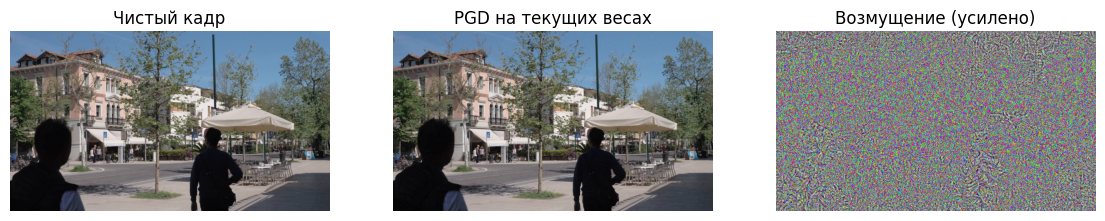

In [ ]:
import time
torch.cuda.synchronize(); begin = time.perf_counter()
adv, diagnostics = tl.pgd_detector(detector,x,target,lab.cfg['epsilon'],5,lab.cfg['attack_step'])
torch.cuda.synchronize(); attack_s = time.perf_counter()-begin
assert diagnostics['linf'] <= lab.cfg['epsilon']+1e-6
assert diagnostics['gradient_mean_abs'] > 0, 'Нулевой градиент: аудит атаки обязателен'
display(pd.DataFrame([diagnostics]))
fig,axes = plt.subplots(1,3,figsize=(14,4))
for ax,img,title in zip(axes,[x,adv,((adv-x)/(2*lab.cfg['epsilon'])+.5).clamp(0,1)],
                        ['Чистый кадр','PGD на текущих весах','Возмущение (усилено)']):
    ax.imshow(img.detach().cpu().permute(1,2,0)); ax.set_title(title); ax.axis('off')
plt.show()

,Вариант,Шагов,Средняя доля PGD,Оценка часов детектора
0,plain,9000,0.00000,0.340216
1,natural,9000,0.00000,0.340216
2,adversarial,9000,0.09975,1.745742


Приближённая оценка по одному кадру; без validation, I/O, ReID и повторов после отключений.


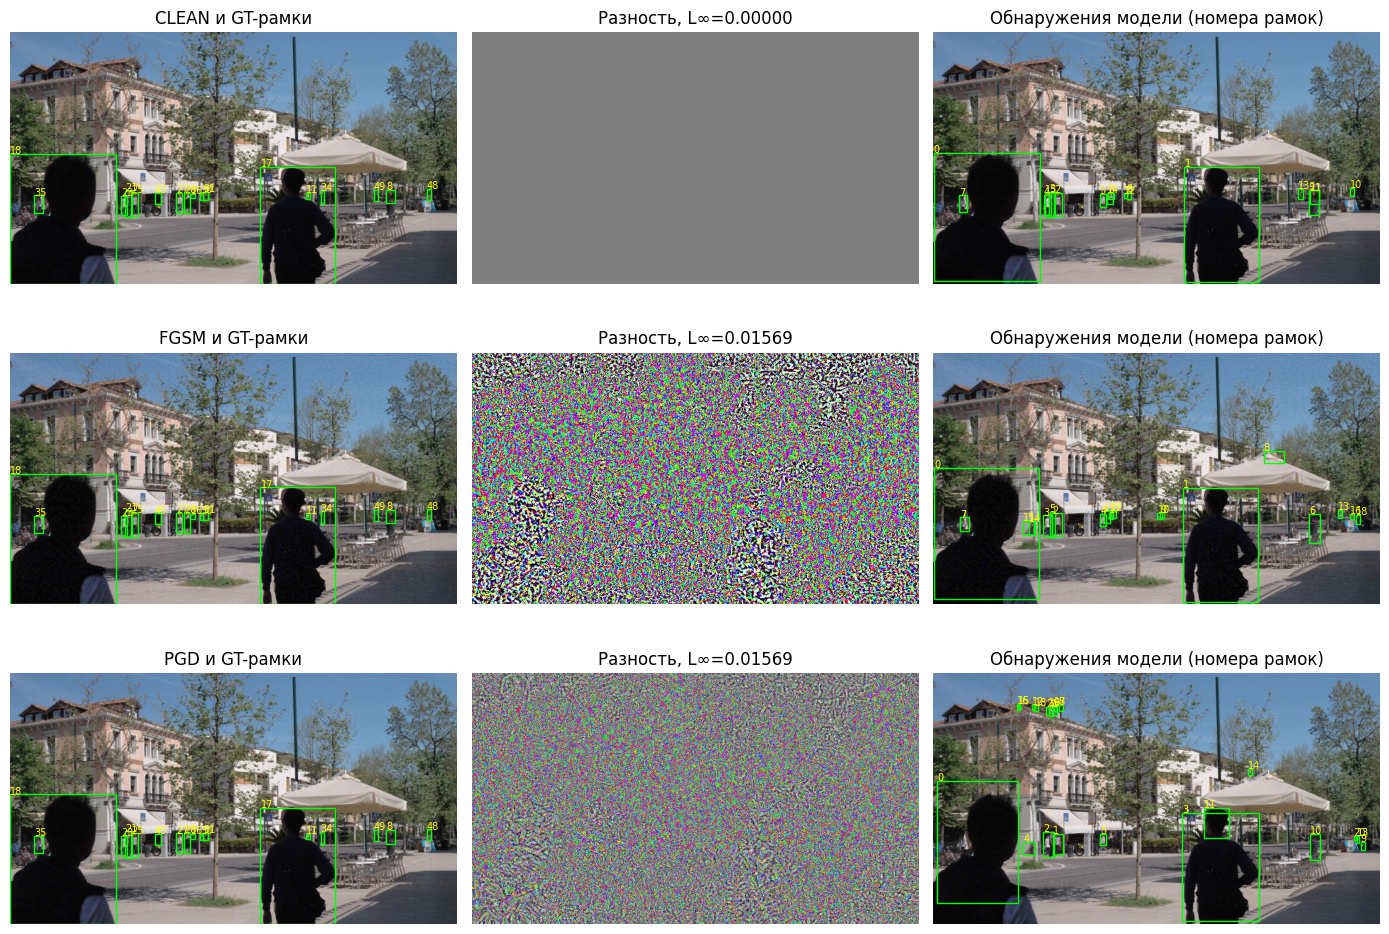

,Атака,Обнаружений,linf,gradient_mean_abs,steps,changed_fraction,clean_loss,attack_loss,loss_gain,mask_fraction,restarts,evaluations,random_start,sampling_seed,objective
0,clean,16,0.000000,0.000000,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,fgsm,19,0.015686,0.000164,1,1.000000,0.904927,1.658417,0.753490,1.0,1.0,3.0,False,1.324457e+09,"maximize detector training loss (surrogate, no..."
2,pgd,22,0.015686,0.000562,5,0.999994,0.904927,4.645916,3.740989,1.0,1.0,7.0,True,1.324457e+09,"maximize detector training loss (surrogate, no..."


,scenario,AP50,precision,recall,small_recall,small_gt,attack_gradient
0,clean,0.801187,0.770737,0.777907,0.613861,303,0.000000
1,photo,0.802783,0.779326,0.780233,0.623762,303,0.000000
2,jpeg,0.783128,0.780774,0.774419,0.617162,303,0.000000
3,noise,0.803850,0.783118,0.776744,0.627063,303,0.000000
4,blur,0.786930,0.779236,0.759302,0.580858,303,0.000000
5,geometry,0.785241,0.745349,0.780755,0.608527,258,0.000000
6,occlusion,0.798437,0.762286,0.775581,0.613861,303,0.000000
7,pgd,0.006244,0.034687,0.047674,0.000000,303,0.001207


In [ ]:
# Pilot выполняет backward одного training-примера без optimizer.step.
detector.zero_grad(set_to_none=True)
torch.cuda.synchronize(); begin = time.perf_counter()
lc = tl.detector_loss(detector,x,target); lc.backward()
torch.cuda.synchronize(); one_view_s = time.perf_counter()-begin
steps = lab.cfg['detector_epochs'] * lab.cfg['detector_steps_per_epoch']
rows=[]
for variant in tl.VARIANTS:
    weights=[tl.cd.probabilities(lab.cfg,variant,p)['pgd'] for p in np.linspace(0,lab.cfg['detector_epochs'],100)]
    pgd_fraction=float(np.mean(weights))
    rows.append({'Вариант':variant,'Шагов':steps,'Средняя доля PGD':pgd_fraction,
        'Оценка часов детектора':steps*(one_view_s+pgd_fraction*attack_s)/3600})
budget=pd.DataFrame(rows)
display(budget)
print('Приближённая оценка по одному кадру; без validation, I/O, ReID и повторов после отключений.')
tl.save_json(lab.path('artifacts/pilot_budget.json'),{'attack_5_steps_seconds':attack_s,'one_view_backward_seconds':one_view_s,'device':torch.cuda.get_device_name(0)})
display(tl.attack_gallery(lab,detector,rec,tl.file_hash(lab.path('checkpoints/initial/detector.pt'))))
initial_validation=tl.validate_detector(lab,detector,tl.validation_subset(lab.records('val'),lab.cfg['augment']['validation_frames_per_video']))
initial_validation.to_csv(lab.path('artifacts/detector_initial_validation.csv'),index=False)
display(initial_validation)
del detector, x, adv, lc
torch.cuda.empty_cache()

Основной рецепт — PGD-5 с random start на текущих весах. Постоянный offline-набор
adversarial JPEG быстро устаревает и здесь не используется. В начале одна эпоха
адаптации без PGD/оптимизированных патчей, затем нарастание доли и ε за две эпохи.
В каждом training-примере одно выбранное воздействие. Валидация сильнее
обучения.
